# Lab 9: Sounding Interpretation
------------
* Due Date: Tuesday, November 10, 2026, 11:59 pm

Work through this notebook in the same team you have been assigned to (color) for the Gradient day.

## Objectives
By the end of this lab you should be able to:
* Read a sounding curve and explain what it suggests about layering.
* Build a layered earth model by adding layers until it fits your data.
* Recognize when adding more layers means you are overfitting the data (i.e. fitting noise)
* Explain why two different models can fit the same data (equivalence), and why thin layers are often difficult/impossible to resolve.
* Explain why AB/2 is not the same as depth.

## Background
These specific lectures might be helpful if you get stuck or need more information/background:
* **14 - DC Survey Design**: how current flows through a layered earth
* **15 - DC Surveying**: soundings and how layers show up in the data
* **17 - Inversions**: pseudo-depth, data misfit, and non-uniqueness

## How this notebook works
* You will **not** need to write code. Each step tells you exactly which numbers to change.
* Questions are marked **Q1, Q2, ...**. So you should be able to follow the notebook top to bottom and answer each of them sequentially in your report.
* Models are always written as two lists (described below), from the surface down:
    * `thicknesses`: the thickness of each layer in meters. The bottom layer is a half space so it goes on forever, so this list is always **one shorter** than the resistivity list. This means that the columns (thick. and resist.) will be uneven in length. 
    * `resistivities`: the resistivity of each layer in Ω·m.

For example, 3 m of 20 Ω·m sitting on top of 6 Ω·m is:
```
thicknesses = [3]
resistivities = [20, 6]
```

## Step 0: Setup
Run the cell below. It should load your Kafadar data and the plotting tools. You do not need to open or edit it. You should see the message "Setup complete."

In [1]:
# ---- Setup: you do not need to edit anything in this cell ----
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from matplotlib.ticker import FuncFormatter, LogLocator
from simpeg.electromagnetics.static import resistivity as dc
from simpeg.electromagnetics.static import utils as static_utils

NOISE_PERCENT = 5   # assumed data uncertainty (%), see Step 1

# Load the Kafadar sounding (V/I in ohms)
_kaf = pd.read_csv('data/kafadar_sounding.csv')
AB2 = _kaf['AB/2'].values
MN2 = _kaf['MN/2'].values
_VI = _kaf['V/I'].values

def _make_survey(ab2, mn2):
    srcs = []
    for a, m in zip(ab2, mn2):
        rx = dc.receivers.Dipole(np.r_[-m, 0., 0.], np.r_[m, 0., 0.], data_type='volt')
        srcs.append(dc.sources.Dipole([rx], np.r_[-a, 0., 0.], np.r_[a, 0., 0.]))
    return dc.Survey(srcs)

_SURVEY = _make_survey(AB2, MN2)
_G = static_utils.geometric_factor(_SURVEY)
RHO_DATA = _VI / _G                      # observed apparent resistivity (ohm m)
_STD = RHO_DATA * NOISE_PERCENT / 100
_MAXZ = 2 * AB2.max()                    # deepest depth shown on plots

def predict(thicknesses, resistivities):
    """Apparent resistivity (ohm m) your model predicts at each AB/2."""
    sim = dc.Simulation1DLayers(survey=_SURVEY, rho=np.asarray(resistivities, float),
                                thicknesses=np.asarray(thicknesses, float))
    return sim.dpred(None) / _G

def misfit(thicknesses, resistivities):
    r = (predict(thicknesses, resistivities) - RHO_DATA) / _STD
    return np.mean(r ** 2)

def _verdict(m):
    if m > 3:
        return 'POOR fit: the model does not match the data within the noise.'
    if m > 1.5:
        return 'CLOSE: getting there, but not yet within the noise.'
    if m >= 0.5:
        return 'GOOD fit: the model matches the data about as well as the noise allows.'
    return 'VERY tight fit: better than the noise. You may be fitting noise.'

def _nice_log_axes(ax):
    """Plain-number tick labels on log axes (e.g. 2, 5, 10, 20 instead of 2x10^0)."""
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
        axis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
        axis.set_minor_formatter(FuncFormatter(lambda v, _: ''))

def _model_xy(thicknesses, resistivities):
    tops = np.r_[0, np.cumsum(thicknesses)]
    bots = np.r_[np.cumsum(thicknesses), np.inf]
    x, y = [], []
    for r, t, b in zip(resistivities, tops, bots):
        if t >= _MAXZ:
            break
        x += [r, r]; y += [max(t, 0.1), min(b, _MAXZ)]
    return x, y

def _plot_data(ax):
    ax.errorbar(RHO_DATA, AB2, xerr=_STD, fmt='k^', ms=6, capsize=2, label='Your data')
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_ylim(_MAXZ, 0.5)
    ax.set_xlabel('Apparent resistivity (Ω·m)')
    ax.set_ylabel('AB/2 (m)')
    ax.grid(True, which='both', alpha=0.3)
    _nice_log_axes(ax)

def plot_data():
    """Plot your sounding curve."""
    fig, ax = plt.subplots(figsize=(5, 6))
    _plot_data(ax)
    ax.set_title('Kafadar sounding curve')
    ax.legend()
    plt.show()

def show_model(thicknesses, resistivities):
    """Show your model (left) and how its prediction compares with your data (right)."""
    if len(thicknesses) != len(resistivities) - 1:
        print('Check your lists: thicknesses must have ONE fewer number than resistivities.')
        return
    pred = predict(thicknesses, resistivities)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 6))
    x, y = _model_xy(thicknesses, resistivities)
    ax1.plot(x, y, 'b-', lw=3)
    ax1.set_xscale('log'); ax1.set_yscale('log')
    ax1.set_ylim(_MAXZ, 0.5)
    ax1.set_xlim(min(min(x), RHO_DATA.min()) / 2, max(max(x), RHO_DATA.max()) * 2)
    ax1.set_xlabel('True resistivity (Ω·m)')
    ax1.set_ylabel('Depth (m)')
    ax1.set_title('Your model')
    ax1.grid(True, which='both', alpha=0.3)
    _nice_log_axes(ax1)
    _plot_data(ax2)
    ax2.plot(pred, AB2, 'r-', lw=2, label="Your model's prediction")
    ax2.set_xlim(ax1.get_xlim())
    ax2.set_title("Data vs. your model's prediction")
    ax2.legend()
    plt.tight_layout(); plt.show()
    m = misfit(thicknesses, resistivities)
    print(f'Misfit = {m:.2f}   (aim for about 1)')
    print(_verdict(m))

def invert(thicknesses, resistivities):
    """Let the computer fine-tune your model, starting from your guess."""
    nl = len(resistivities)
    x0 = np.log(np.r_[resistivities, thicknesses].astype(float))
    lo = np.r_[np.full(nl, np.log(0.1)), np.full(nl - 1, np.log(0.05))]
    hi = np.r_[np.full(nl, np.log(1e4)), np.full(nl - 1, np.log(500))]
    x0 = np.clip(x0, lo + 1e-6, hi - 1e-6)
    def resid(x):
        return (predict(np.exp(x[nl:]), np.exp(x[:nl])) - RHO_DATA) / _STD
    sol = least_squares(resid, x0, bounds=(lo, hi))
    rho = [round(float(v), 1) for v in np.exp(sol.x[:nl])]
    thk = [round(float(v), 2) for v in np.exp(sol.x[nl:])]
    print('Best-fitting model:')
    print('  thicknesses   =', thk, '(m)')
    print('  resistivities =', rho, '(Ω·m)')
    if np.sum(thk) > AB2.max():
        print('  Note: a layer boundary is deeper than your largest AB/2. Your data cannot really see that deep.')
    show_model(thk, rho)
    return thk, rho

def add_thin_layer(thicknesses, resistivities, top, h, rho_new):
    """Insert a layer of thickness h (m) and resistivity rho_new, starting at depth top (m)."""
    bounds = list(np.cumsum(thicknesses))
    edges = sorted(set([b for b in bounds if b > 0] + [top, top + h]))
    def rho_at(z):
        return resistivities[int(np.searchsorted(bounds, z))]
    tops = [0] + edges
    bots = edges + [np.inf]
    new_rho = []
    for t, b in zip(tops, bots):
        mid = t + 1e-6 if np.isinf(b) else (t + b) / 2
        new_rho.append(rho_new if top <= mid < top + h else rho_at(mid))
    return list(np.diff([0] + edges)), new_rho

def compare_curves(models, labels, title, show_data=True):
    """Plot several models (left) and their predicted curves (right)."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 6))
    for (t, r), lab in zip(models, labels):
        x, y = _model_xy(t, r)
        ax1.plot(x, y, lw=2, label=lab)
        ax2.plot(predict(t, r), AB2, lw=2, label=lab)
    ax1.set_xscale('log'); ax1.set_yscale('log'); ax1.set_ylim(_MAXZ, 0.5)
    ax1.set_xlabel('True resistivity (Ω·m)'); ax1.set_ylabel('Depth (m)')
    ax1.set_title('Models'); ax1.grid(True, which='both', alpha=0.3); ax1.legend(fontsize=8)
    _nice_log_axes(ax1)
    if show_data:
        _plot_data(ax2)
    else:
        ax2.set_xscale('log'); ax2.set_yscale('log'); ax2.set_ylim(_MAXZ, 0.5)
        ax2.set_xlabel('Apparent resistivity (Ω·m)'); ax2.set_ylabel('AB/2 (m)')
        ax2.grid(True, which='both', alpha=0.3)
        _nice_log_axes(ax2)
    ax2.set_title(title); ax2.legend(fontsize=8)
    plt.tight_layout(); plt.show()

print('Setup complete.')

Setup complete.


## Step 1: Look at your data
Run the cell below to plot your Kafadar sounding. Each triangle is one reading. The horizontal bars show the uncertainty we are assuming for each reading (5%).

**You might be wondering 'why 5%?'** The Sting often reported errors under 2 and 1%, but when you changed MN/2 at the same AB/2, the readings jumped by up to about 10%. So the real uncertainty is larger than the Sting's number, and 5% is a reasonable middle estimate.

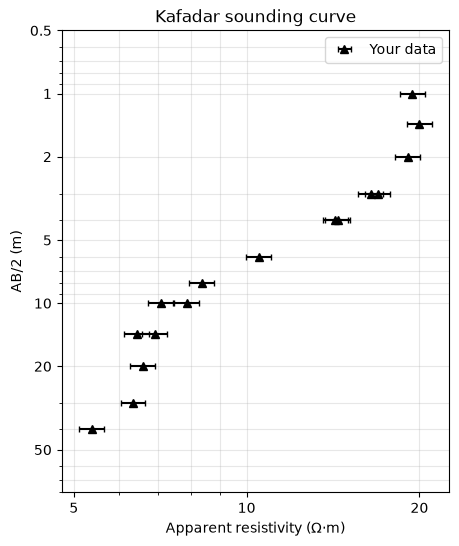

In [2]:
plot_data()

**Q1.** How does apparent resistivity change as AB/2 gets larger? Roughly what is it at the smallest AB/2, and at the largest?

**Q2.** Based on the shape alone, is there something more resistive or more conductive at depth? How can you tell?

## Before you start modeling: what is the computer comparing?

From here on, you will build models of the earth and compare them with your data. Here is what happens every time you run a cell:

1. **You build a model.** You type in layer thicknesses and resistivities. This is your guess at what the earth under Kafadar looks like. It has sharp layers and true depths (left panel).
2. **The computer runs a forward model.** It calculates what you *would have measured* with your exact electrode spacings if the earth looked like your model. 
3. **It compares the prediction with your real data.** The predicted readings are the red line (right panel). Your actual readings are the black triangles. The misfit give you a quantitative measure of how far apart they are.

## Step 2: Try one layer
The simplest possible earth is a single uniform layer (a half-space). It has no thicknesses, just one resistivity.

Run the cell. Then try a few different values for the resistivity and run it again each time.

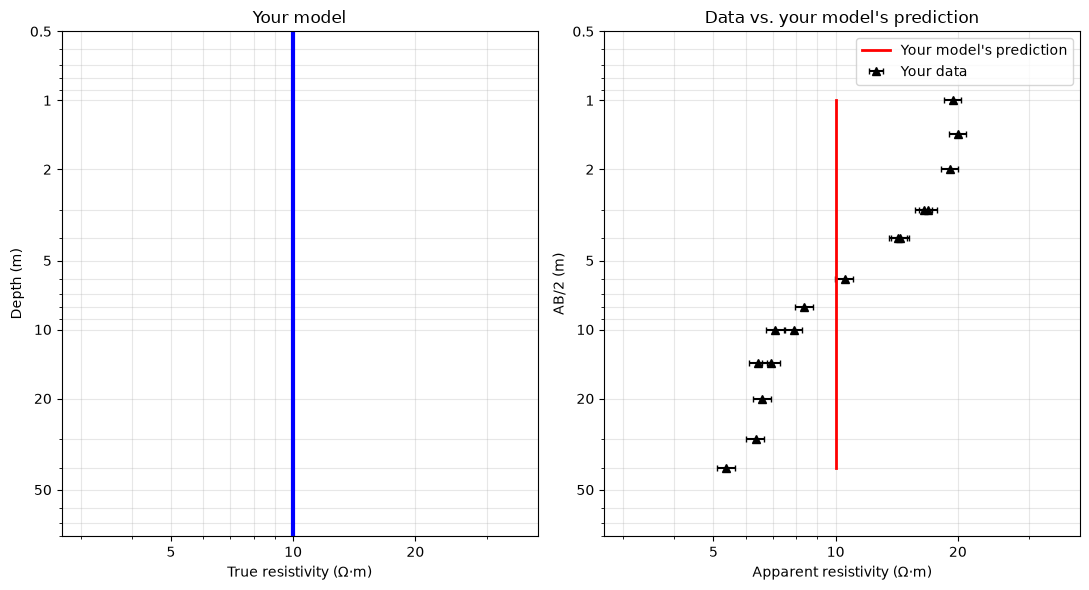

Misfit = 83.36   (aim for about 1)
POOR fit: the model does not match the data within the noise.


In [5]:
thicknesses = []
resistivities = [10]      # <-- try a few values here to change the resist. of the halfspace (try to get your misft down!)

show_model(thicknesses, resistivities)

**How to read these plots:**
* **Left, "Your model":** the earth you built. Depth goes down, true resistivity goes across.
* **Right, "Data vs. your model's prediction":** black triangles are your data, the red line is what your model predicts you would measure.
* **Misfit:** how far apart the red line and the triangles are, compared with the noise. About 1 is a good fit.

**Q3.** What is the best misfit you could get with one layer? Why can't a single layer fit your data?

## Step 3: Two layers, by hand
Now add a second layer. You need three numbers: the top layer's resistivity, its thickness, and the bottom layer's resistivity.

**Hints for a first guess:**
* The **top layer** controls the readings at small AB/2. Start with a value close to your first few readings.
* The **bottom layer** controls the readings at large AB/2. Start with a value close to your last few readings (it is often a bit beyond them).
* For the **thickness**, look at where your curve bends. Try a few values and watch where the red line bends.

Change the numbers and rerun until the red line follows the triangles as well as you can. Aim for a misfit under 3.

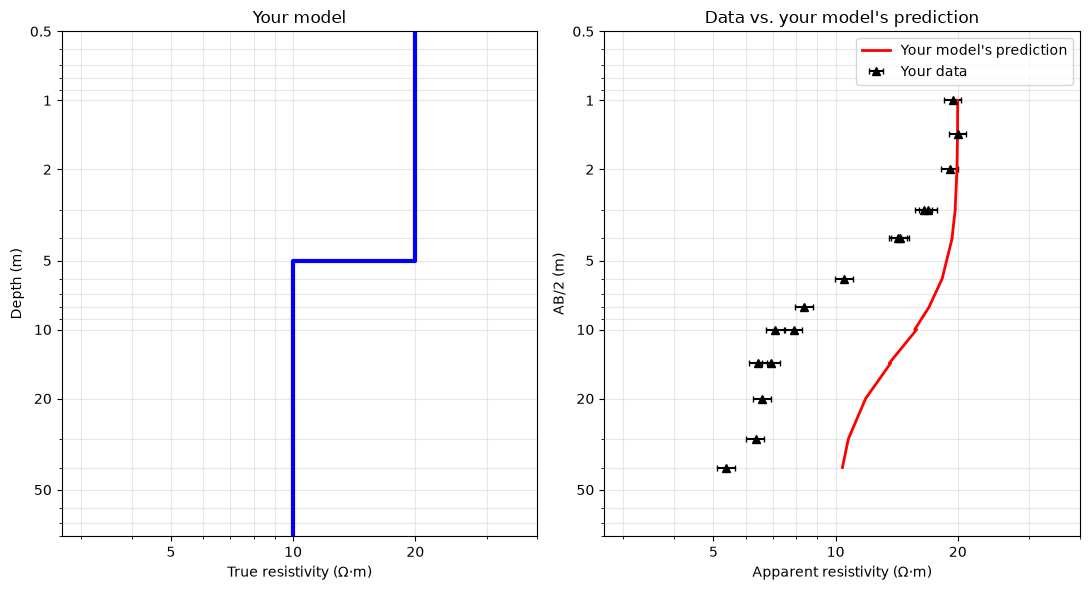

Misfit = 213.64   (aim for about 1)
POOR fit: the model does not match the data within the noise.


In [11]:
thicknesses = [5]           # <-- thickness of the top layer (m)
resistivities = [20, 10]    # <-- [top layer, bottom layer] (Ω·m)

show_model(thicknesses, resistivities)

**Q4.** Write down your best hand-fit model (top resistivity, thickness, bottom resistivity) and its misfit. Which number had the biggest effect on the fit?

## Step 4: Let the computer fine-tune it
Fitting by hand is slow. An **inversion** does the same thing you just did: it adjusts the numbers until the misfit is as small as possible. It starts from your guess.

Copy your best hand-fit numbers into the cell below and run it.

**NOTE** Here, "Your model's prediction" refers to the inversions best-fitting model which will be listed below once run

Best-fitting model:
  thicknesses   = [2.24] (m)
  resistivities = [20.1, 6.0] (Ω·m)


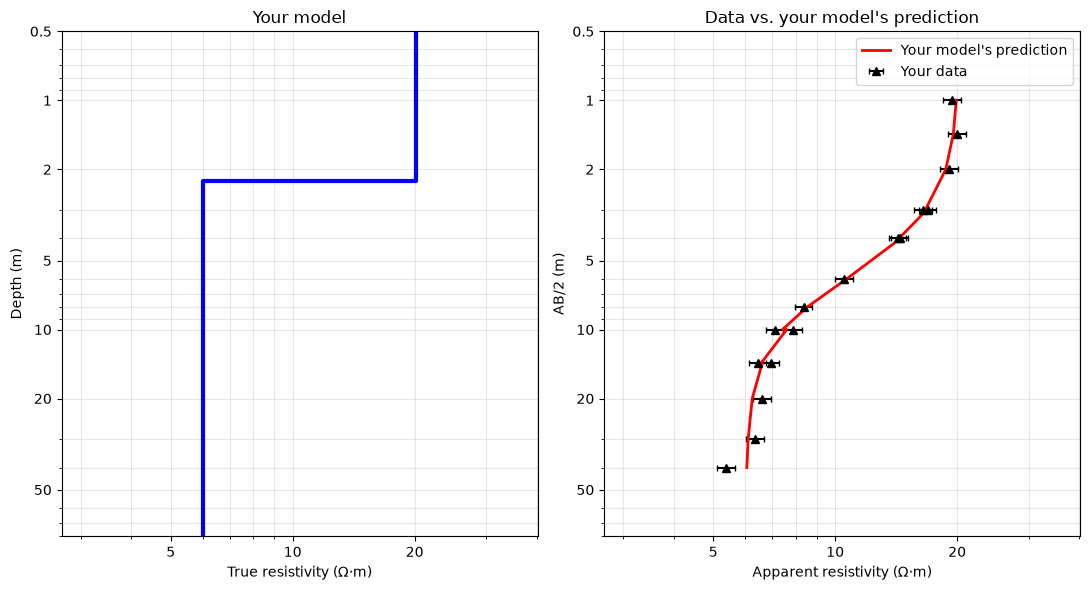

Misfit = 0.73   (aim for about 1)
GOOD fit: the model matches the data about as well as the noise allows.


In [13]:
thicknesses = [5]           # <-- your hand-fit thickness
resistivities = [20, 10]    # <-- your hand-fit resistivities

best_2_thick, best_2_rho = invert(thicknesses, resistivities)

**Q5.** How does the computer's model compare with your hand fit? Is the misfit now about 1? What does the 2-layer model say about Kafadar (thickness and resistivity of each layer)?

## Step 5: Do we need a third layer?
Maybe there is more going on. Add a third layer and invert again. A starting guess is filled in for you; feel free to change it.

Best-fitting model:
  thicknesses   = [2.1, 42.04] (m)
  resistivities = [20.4, 6.3, 0.1] (Ω·m)
  Note: a layer boundary is deeper than your largest AB/2. Your data cannot really see that deep.


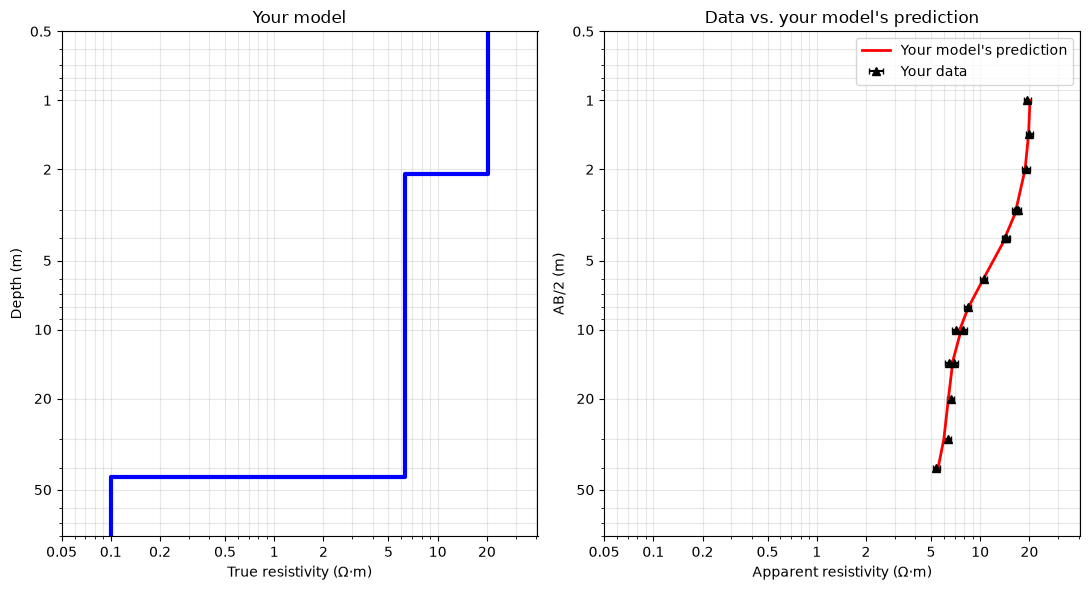

Misfit = 0.37   (aim for about 1)
VERY tight fit: better than the noise. You may be fitting noise.


In [14]:
thicknesses = [1, 4]            # <-- [layer 1, layer 2] thicknesses (m)
resistivities = [20, 10, 6]     # <-- [layer 1, layer 2, layer 3] (Ω·m)

best_3_thick, best_3_rho = invert(thicknesses, resistivities)

Now compare the fits side by side:

In [15]:
print(f"1 layer:  misfit = {min(misfit([], [r]) for r in np.logspace(0, 2, 200)):.2f}")
print(f"2 layers: misfit = {misfit(best_2_thick, best_2_rho):.2f}")
print(f"3 layers: misfit = {misfit(best_3_thick, best_3_rho):.2f}")

1 layer:  misfit = 62.18
2 layers: misfit = 0.73
3 layers: misfit = 0.37


**Q6.** How much did the misfit improve going from 1 to 2 layers? From 2 to 3?

**Q7.** Is the third layer real, or is it just fitting the noise? How many layers do you think your data actually support, and why?

## Step 6: Can a thin layer hide?
Suppose there is a thin **clay** layer (2 Ω·m) buried 5 m down inside your 2-layer earth. Would your sounding see it?

The cell below adds that layer to your best 2-layer model and makes it thinner and thinner. For each thickness, it prints how much the curve changes compared with no thin layer. If the change is smaller than the noise (5%), the layer is effectively **invisible**.

thickness =  4.00 m   thickness/depth = 0.80   curve changes by  35.9 %   -> visible
thickness =  2.00 m   thickness/depth = 0.40   curve changes by  24.0 %   -> visible
thickness =  1.00 m   thickness/depth = 0.20   curve changes by  14.2 %   -> visible
thickness =  0.50 m   thickness/depth = 0.10   curve changes by   7.7 %   -> visible
thickness =  0.25 m   thickness/depth = 0.05   curve changes by   4.0 %   -> INVISIBLE (smaller than the noise)


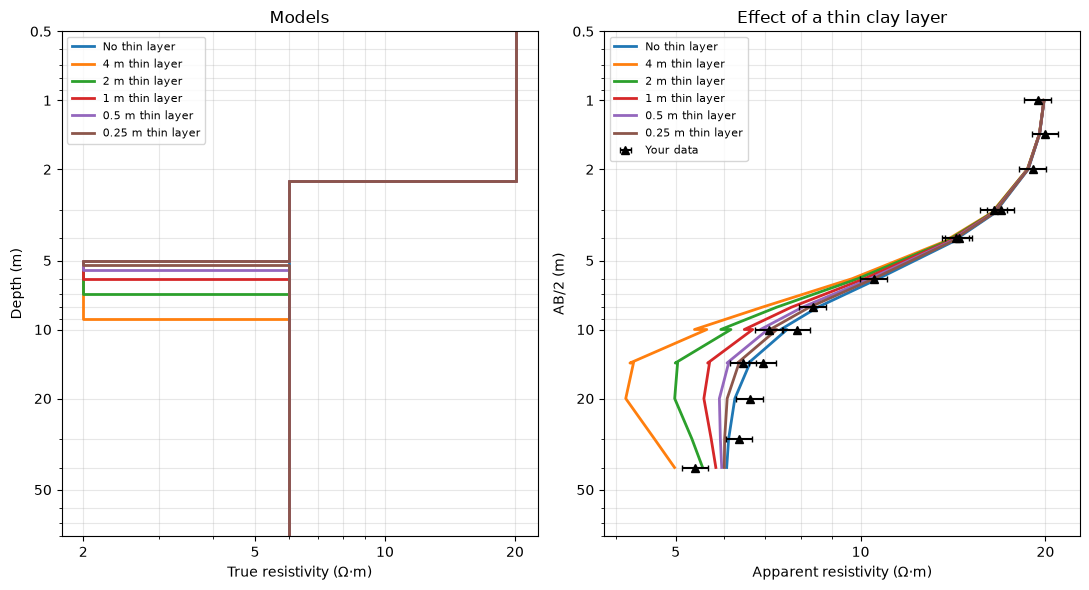

In [16]:
layer_depth = 5                         # depth to the top of the thin layer (m)
layer_rho = 2                           # resistivity of the thin layer (Ω·m)
thin_thicknesses = [4, 2, 1, 0.5, 0.25]   # <-- thicknesses to try (m)

base = predict(best_2_thick, best_2_rho)
models, labels = [(best_2_thick, best_2_rho)], ['No thin layer']
for h in thin_thicknesses:
    t, r = add_thin_layer(best_2_thick, best_2_rho, layer_depth, h, layer_rho)
    change = np.max(np.abs(predict(t, r) - base) / base) * 100
    status = 'visible' if change > NOISE_PERCENT else 'INVISIBLE (smaller than the noise)'
    print(f'thickness = {h:5.2f} m   thickness/depth = {h/layer_depth:4.2f}   curve changes by {change:5.1f} %   -> {status}')
    models.append((t, r)); labels.append(f'{h} m thin layer')

compare_curves(models, labels, 'Effect of a thin clay layer')

**Q8.** At what thickness does the thin layer become invisible? What is its thickness divided by its depth at that point? What does this tell you about what a sounding can and cannot detect?

## Step 7: Two different earths, the same data (equivalence)
This step uses three synthetic models with the same electrode spacings as your survey. Each has 5 m of 20 Ω·m on top of a **conductive** layer, sitting on 50 Ω·m. The conductive layer is different in each model:

| Model | Conductive layer thickness | Conductive layer resistivity |
|---|---|---|
| A | 2 m | 4 Ω·m |
| B | 1 m | 2 Ω·m |
| C | 0.5 m | 1 Ω·m |

All three have the same thickness ÷ resistivity (0.5), which is called the **longitudinal conductance**. Run the cell and compare them.

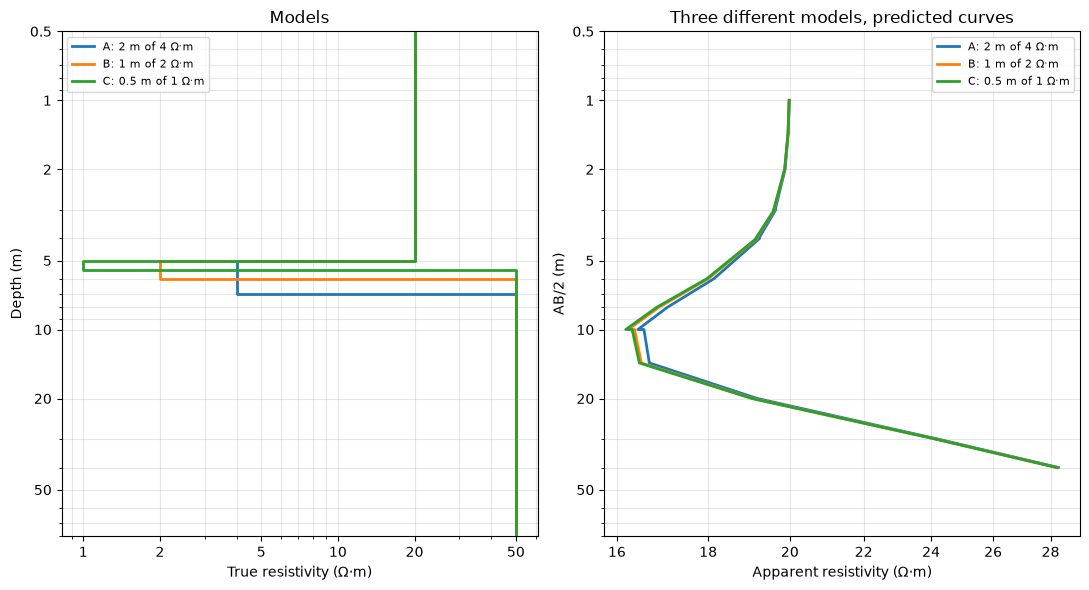

Model B differs from model A by at most 1.2 %  (our noise is 5 %)
Model C differs from model A by at most 1.6 %  (our noise is 5 %)


In [17]:
model_A = ([5, 2],   [20, 4, 50])
model_B = ([5, 1],   [20, 2, 50])
model_C = ([5, 0.5], [20, 1, 50])

compare_curves([model_A, model_B, model_C],
               ['A: 2 m of 4 Ω·m', 'B: 1 m of 2 Ω·m', 'C: 0.5 m of 1 Ω·m'],
               'Three different models, predicted curves', show_data=False)

base = predict(*model_A)
for name, m in [('B', model_B), ('C', model_C)]:
    diff = np.max(np.abs(predict(*m) - base) / base) * 100
    print(f'Model {name} differs from model A by at most {diff:.1f} %  (our noise is {NOISE_PERCENT} %)')

**Q9.** How different are the three models? How different are their predicted curves compared with the noise? If you measured one of these curves, could you tell which model is the real earth?

**Q10.** Thinking about how current flows: why does a thin, very conductive layer act like a thicker, less conductive one? (Hint: conductances add in parallel.)

## Step 8: AB/2 is not depth
The cell below draws your best model on top of your sounding curve, on the same axes. The vertical axis is AB/2 for the data and depth for the model.

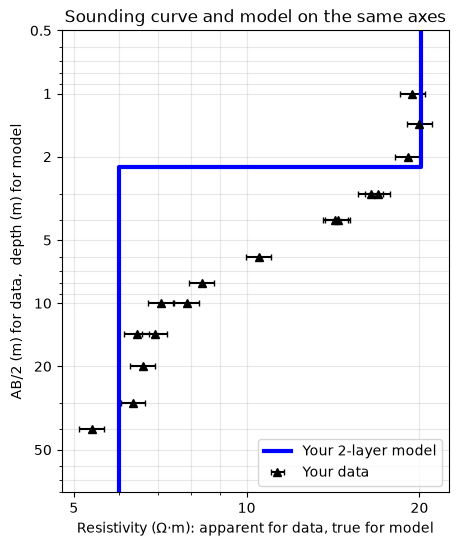

In [18]:
fig, ax = plt.subplots(figsize=(5, 6))
_plot_data(ax)
x, y = _model_xy(best_2_thick, best_2_rho)
ax.plot(x, y, 'b-', lw=3, label='Your 2-layer model')
ax.set_xlabel('Resistivity (Ω·m): apparent for data, true for model')
ax.set_ylabel('AB/2 (m) for data,  depth (m) for model')
ax.set_title('Sounding curve and model on the same axes')
ax.legend(loc='lower right')
plt.show()

**Q11.** At what depth is the layer boundary in your model? At what AB/2 does your sounding curve bend the most? Are they the same?

**Q12.** Are the resistivities in your model the same as the apparent resistivities you measured? Why or why not?

## Step 9: Interpret
**Q13.** What might be beneath Kafadar to produce your model? Think about topsoil, fill, irrigation, moisture, clay, the water table, and the local geology. Use your numbers (thicknesses and resistivities) to support your answer.

# Lab 9 Deliverables
Submit an informal report (one per color team) that includes:

1. Your names, color team, and lab title
2. A short description of the objectives
3. Answers to **Q1 to Q13**, with the figures that support them. Every figure needs a caption.
4. Your final preferred model in a small table (thickness and resistivity of each layer)
5. A short concluding paragraph: what did you learn about how layers, thickness, and resistivity show up (or hide) in a sounding?